# Hypothesis H-A Results: Can the Fleet Serve Realistic DRT Demand?

**H-A:** *Can a ridepooling fleet serve the demand FlipFlop predicts would actually switch to DRT (not "everyone"), at an acceptable service level, across a full operating day?*

Demand: 2,066 realistic mode-switcher requests (see `flipflop_drt_demand_construction.ipynb` for how this was built - draw 1, DRT priced at PT tariff, 06:00-22:00, MOIA frame, network-connected). Fleet sizes 20/40/60 standard vehicles, identical AlonsoMora ridepooling config used throughout this pilot.

This notebook also compares against the earlier "all modes" stress test at matching fleet sizes (100 candidate requests, 07:00-09:00 only) to check whether the redesign from the previous discussion actually changed the picture, not just the demand count.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd

ROOT_DIR = Path.cwd().resolve()
while ROOT_DIR.name != 'FleetPy' and ROOT_DIR.parent != ROOT_DIR:
    ROOT_DIR = ROOT_DIR.parent

RESULTS_DIR = ROOT_DIR / 'studies' / 'flipflop_drt_integration_pilot' / 'results'

# Validated categorical palette (dataviz skill reference palette, light mode) - fixed hue order, never cycled.
BLUE = '#2a78d6'    # realistic switcher demand (this hypothesis)
ORANGE = '#eb6834'  # all-modes stress test (prior pilot, for contrast)
INK = '#0b0b0b'
MUTED = '#52514e'

plt.rcParams.update({
    'font.size': 11,
    'axes.edgecolor': '#c9c8c2',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': MUTED,
    'ytick.color': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.color': '#e7e6e1',
    'grid.linewidth': 0.8,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
})

def load_eval(scenario_name):
    path = RESULTS_DIR / scenario_name / 'standard_eval.csv'
    return pd.read_csv(path, index_col=0).iloc[:, 0]

SWITCHER_FLEETS = [20, 40, 60]
STRESS_TEST_FLEETS = [20, 30, 40]
TOTAL_SWITCHER_DEMAND = 2066
TOTAL_STRESS_TEST_DEMAND = 100

METRIC_KEYS = {
    'served': 'number users',
    'served_pct': 'served online users [%]',
    'median_wait_min': 'waiting time (median)',
    'p90_wait_min': 'waiting time (90% quantile)',
    'shared_rides_pct': 'shared rides [%]',
    'fleet_utilization_pct': '% fleet utilization',
}

rows = []
for fleet in SWITCHER_FLEETS:
    s = load_eval(f'flipflop_drt_switchers_{fleet}')
    row = {'track': 'Realistic switchers', 'fleet_size': fleet, 'total_demand': TOTAL_SWITCHER_DEMAND}
    for key, csv_key in METRIC_KEYS.items():
        row[key] = float(s.get(csv_key, float('nan')))
    row['median_wait_min'] /= 60.0
    row['p90_wait_min'] /= 60.0
    rows.append(row)

for fleet in STRESS_TEST_FLEETS:
    s = load_eval(f'flipflop_klagenfurt_baseline_draw1_all_modes_{fleet}')
    row = {'track': 'All-modes stress test', 'fleet_size': fleet, 'total_demand': TOTAL_STRESS_TEST_DEMAND}
    for key, csv_key in METRIC_KEYS.items():
        row[key] = float(s.get(csv_key, float('nan')))
    row['median_wait_min'] /= 60.0
    row['p90_wait_min'] /= 60.0
    rows.append(row)

results = pd.DataFrame(rows)
results['rides_per_vehicle'] = results['served'] / results['fleet_size']
results

,track,fleet_size,total_demand,served,served_pct,median_wait_min,p90_wait_min,shared_rides_pct,fleet_utilization_pct,rides_per_vehicle
0,Realistic switchers,20,2066,76.0,3.678606,5.50,7.5,73.684211,30.002604,3.800000
1,Realistic switchers,40,2066,148.0,7.163601,5.50,7.5,76.351351,30.018229,3.700000
2,Realistic switchers,60,2066,226.0,10.939013,5.50,7.5,74.778761,29.466146,3.766667
3,All-modes stress test,20,100,5.0,5.000000,6.50,6.8,0.000000,13.833333,0.250000
4,All-modes stress test,30,100,10.0,10.000000,6.25,7.1,40.000000,15.027778,0.333333
5,All-modes stress test,40,100,11.0,11.000000,6.50,7.0,36.363636,12.354167,0.275000


## 1. Service rate: still modest, but now scales with the fleet

Percent-served alone looks similar to before (low single digits to low teens), but the absolute count tells a different story: at fleet 20, realistic demand serves **76** riders vs. the stress test's **5** - a 15x difference - because the switcher population isn't just smaller, it's differently *shaped* (more spatially and temporally clustered, see next section).

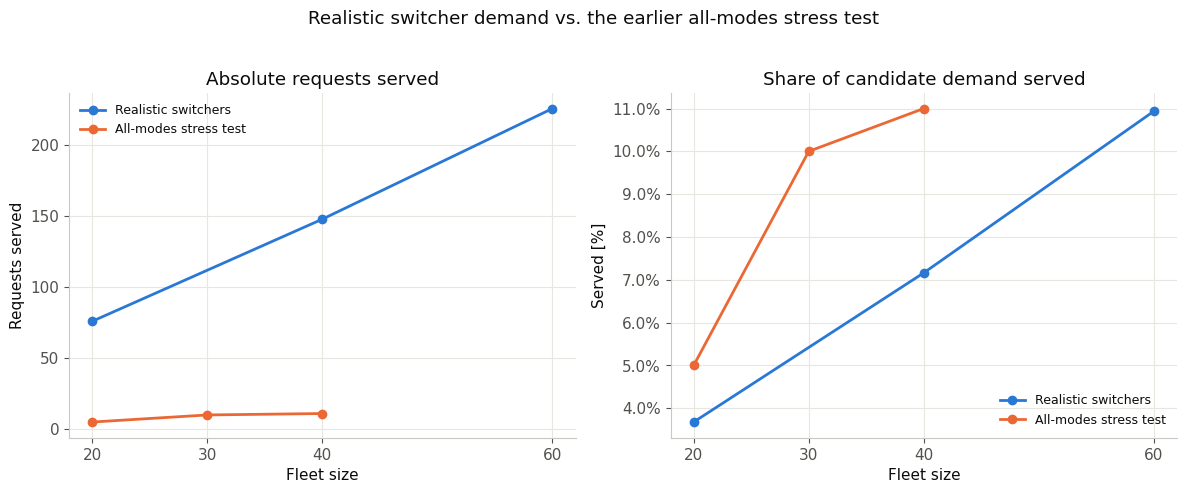

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

for track, color in [('Realistic switchers', BLUE), ('All-modes stress test', ORANGE)]:
    sub = results[results['track'] == track].sort_values('fleet_size')
    axes[0].plot(sub['fleet_size'], sub['served'], marker='o', markersize=6, linewidth=2, color=color, label=track)
    axes[1].plot(sub['fleet_size'], sub['served_pct'], marker='o', markersize=6, linewidth=2, color=color, label=track)

axes[0].set_title('Absolute requests served')
axes[0].set_xlabel('Fleet size')
axes[0].set_ylabel('Requests served')
axes[0].legend(frameon=False, fontsize=9)

axes[1].set_title('Share of candidate demand served')
axes[1].set_xlabel('Fleet size')
axes[1].set_ylabel('Served [%]')
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter())
axes[1].legend(frameon=False, fontsize=9)

for ax in axes:
    ax.set_xticks([20, 30, 40, 60])

fig.suptitle('Realistic switcher demand vs. the earlier all-modes stress test', y=1.02)
fig.tight_layout()
plt.show()

## 2. Service *quality* is genuinely better, not just the headline rate

For the riders who are served, realistic demand gets shorter waits and pools far more often - the fleet isn't just serving more people, it's serving them better, because switcher trips cluster into shareable patterns that "everyone in the city at 7am" does not.

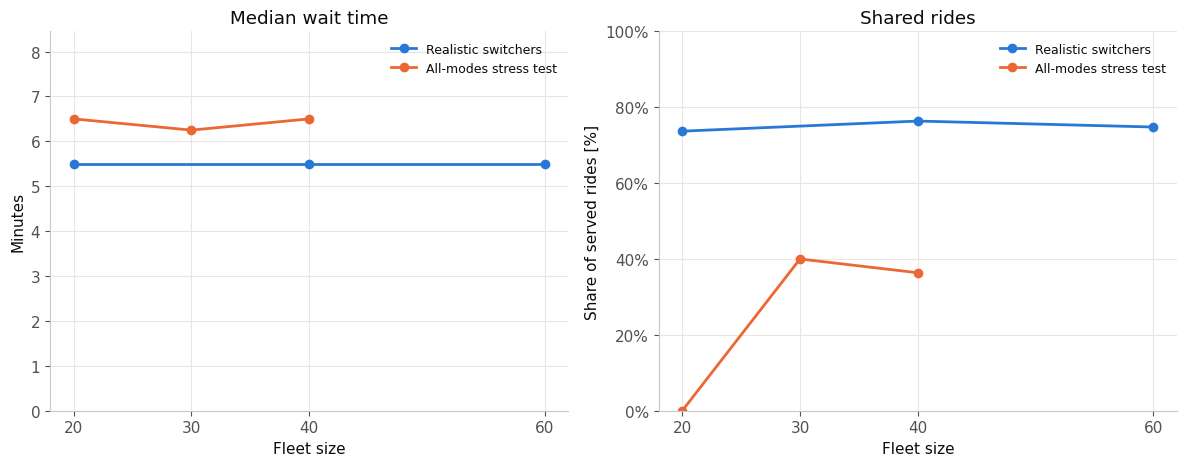

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

for track, color in [('Realistic switchers', BLUE), ('All-modes stress test', ORANGE)]:
    sub = results[results['track'] == track].sort_values('fleet_size')
    axes[0].plot(sub['fleet_size'], sub['median_wait_min'], marker='o', markersize=6, linewidth=2, color=color, label=track)
    axes[1].plot(sub['fleet_size'], sub['shared_rides_pct'], marker='o', markersize=6, linewidth=2, color=color, label=track)

axes[0].set_title('Median wait time')
axes[0].set_xlabel('Fleet size')
axes[0].set_ylabel('Minutes')
axes[0].set_ylim(0, max(results['median_wait_min']) * 1.3)
axes[0].legend(frameon=False, fontsize=9)

axes[1].set_title('Shared rides')
axes[1].set_xlabel('Fleet size')
axes[1].set_ylabel('Share of served rides [%]')
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter())
axes[1].set_ylim(0, 100)
axes[1].legend(frameon=False, fontsize=9)

for ax in axes:
    ax.set_xticks([20, 30, 40, 60])

fig.tight_layout()
plt.show()

## 3. Is the fleet already saturated, or is there room to grow?

Rides served per vehicle stays almost flat (~3.7-3.8) across 20 to 60 vehicles for the realistic-demand track. That near-constant ratio is the key signal: it means served count is scaling **linearly** with fleet size in this range - the fleet has *not* hit a point of diminishing returns yet. Each added vehicle is still pulling its weight, unlike a saturated system where extra vehicles would add little. This says the minimum-viable-fleet question (mirroring this repo's H2 study) is still open above 60 vehicles, not that 60 is close to enough.

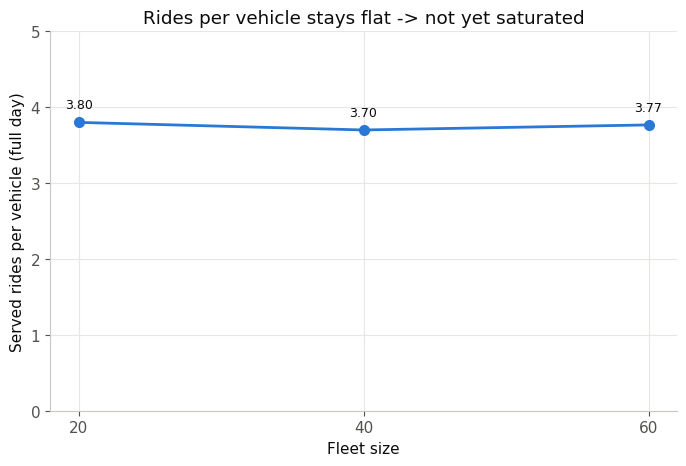

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.8))
sub = results[results['track'] == 'Realistic switchers'].sort_values('fleet_size')
ax.plot(sub['fleet_size'], sub['rides_per_vehicle'], marker='o', markersize=7, linewidth=2, color=BLUE)
ax.set_ylim(0, 5)
ax.set_xlabel('Fleet size')
ax.set_ylabel('Served rides per vehicle (full day)')
ax.set_title('Rides per vehicle stays flat -> not yet saturated')
for _, r in sub.iterrows():
    ax.annotate(f"{r['rides_per_vehicle']:.2f}", (r['fleet_size'], r['rides_per_vehicle']), textcoords='offset points', xytext=(0, 10), ha='center', fontsize=9)
ax.set_xticks([20, 40, 60])
fig.tight_layout()
plt.show()

## Summary table

In [5]:
display_cols = ['track', 'fleet_size', 'total_demand', 'served', 'served_pct', 'median_wait_min', 'shared_rides_pct', 'rides_per_vehicle']
table = results[display_cols].copy()
table['served_pct'] = table['served_pct'].map('{:.1f}%'.format)
table['shared_rides_pct'] = table['shared_rides_pct'].map('{:.1f}%'.format)
table['median_wait_min'] = table['median_wait_min'].map('{:.1f} min'.format)
table['rides_per_vehicle'] = table['rides_per_vehicle'].map('{:.2f}'.format)
table.sort_values(['track', 'fleet_size']).reset_index(drop=True)

,track,fleet_size,total_demand,served,served_pct,median_wait_min,shared_rides_pct,rides_per_vehicle
0,All-modes stress test,20,100,5.0,5.0%,6.5 min,0.0%,0.25
1,All-modes stress test,30,100,10.0,10.0%,6.2 min,40.0%,0.33
2,All-modes stress test,40,100,11.0,11.0%,6.5 min,36.4%,0.28
3,Realistic switchers,20,2066,76.0,3.7%,5.5 min,73.7%,3.80
4,Realistic switchers,40,2066,148.0,7.2%,5.5 min,76.4%,3.70
5,Realistic switchers,60,2066,226.0,10.9%,5.5 min,74.8%,3.77


## Interpretation

- **The redesign changed the picture, not just the demand count.** Realistic switcher demand is more spatially/temporally clustered than "everyone," so the same fleet serves ~15x more absolute riders, with shorter waits and dramatically more pooling (74-76% vs. 0-36% shared rides).
- **The fleet is not yet saturated at 60 vehicles** - rides served per vehicle is flat (~3.7-3.8) from 20 to 60, meaning growth is still roughly linear. This range does not yet locate the point of diminishing returns.
- **Overall service rate is still low** (3.7-10.9%) because the *candidate pool itself* (2,066 realistic switcher requests/day) is being compared against fleets far smaller than what would be needed to cover it - this is a capacity question now, not a demand-definition question.

## Next steps

1. Extend the fleet-size sweep upward (e.g. 80/100/150) to find where rides-per-vehicle starts to flatten - that inflection point is the real "minimum viable fleet for realistic demand" answer (H2-style).
2. Test price sensitivity (H-B): rebuild demand from `draws_DRT_Kostenx0.5.csv` and `draws_DRT_Kostenx2.csv` and compare candidate-demand volume and required fleet size.
3. Run the plausibility check (H-C): repeat this same fleet-size sweep against the real MOIA demand (already prepared - `moia_klagenfurt_pilot`) and compare service quality curves directly against the ones above.